# 03. Classification - Crop Recommendation

## 1. Mục tiêu

Xây dựng mô hình **Supervised Classification** để dự đoán loại cây trồng dựa trên các đặc trưng về đất và khí hậu.

Các đặc trưng đầu vào gồm:

- `N`: Hàm lượng Nitơ trong đất
- `P`: Hàm lượng Photpho trong đất
- `K`: Hàm lượng Kali trong đất
- `temperature`: Nhiệt độ
- `humidity`: Độ ẩm
- `ph`: Độ pH
- `rainfall`: Lượng mưa

Dữ liệu đầu vào là dữ liệu đã được làm sạch, mã hóa và chia thành tập Train/Test bởi Thành viên 2, được lưu trong thư mục `data/processed/`.

## 2. Mô hình sử dụng

Hai thuật toán được sử dụng để thực nghiệm và so sánh:

1. **Random Forest** – mô hình chính.
2. **Support Vector Machine (SVM)** – mô hình so sánh.

## 3. Tiêu chí đánh giá

Các mô hình được đánh giá dựa trên:

- Accuracy - Độ chính xác tổng thể
- Precision - Độ chuẩn xác
- Recall - Độ bao phủ
- Confusion Matrix - Ma trận nhầm lẫn
- Thời gian huấn luyện và dự đoán

## 4. Cài đặt và import thư viện

Các thư viện được sử dụng để đọc dữ liệu, xây dựng mô hình Machine Learning, đánh giá kết quả và trực quan hóa kết quả thực nghiệm.

> Lưu ý: Project đã có file `requirements.txt` để quản lý các thư viện cần thiết.

In [1]:
import os      # thư viện tương tác hệ điều hành
import time    # thư viện xử lý tg
import joblib  # thư viện lưu mô hình học máy
import numpy as np   #  thư viện chuyên tính toán số học, mảng đa chiều
import pandas as pd  # thư viện chuyên đọc, xử lý và thao tác dữ liệu dạng bảng 
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier   # mô hình thuật toán phân loại Rừng ngẫu nhiên
from sklearn.svm import SVC   # mô hình thuật toán Máy cực đại véc-tơ hỗ trợ
from sklearn.metrics import (
    accuracy_score,  #  Hàm tính tỷ lệ dự đoán chính xác tổng thể.
    precision_score, # Hàm tính độ chuẩn xác (tỷ lệ đoán đúng trên số lần đoán "Có").
    recall_score,    # Hàm tính độ bao phủ (tỷ lệ đoán ra được bao nhiêu phần trăm trên thực tế).
    classification_report,  # Hàm tạo báo cáo tổng hợp các chỉ số trên một cách chi tiết cho từng loại cây.
    confusion_matrix  # Hàm tính toán Ma trận nhầm lẫn để xem mô hình hay nhầm lẫn loại cây nào với nhau.  
)   # công cụ đánh giá mô hình

print("Import thư viện thành công!")

Import thư viện thành công!


## 5. Đọc dữ liệu

Dữ liệu đã được xử lý từ bước Preprocessing và được lưu thành các file:

- `X_train.csv`: tập đặc trưng dùng để huấn luyện.
- `X_test.csv`: tập đặc trưng dùng để kiểm thử.
- `y_train.csv`: nhãn tương ứng với tập Train.
- `y_test.csv`: nhãn tương ứng với tập Test.
- `label_mapping.csv`: bảng ánh xạ giữa mã số và tên loại cây.

Các file được đọc từ thư mục `data/processed/`.

In [2]:
DATA_PATH = "../data/processed/"

X_train = pd.read_csv(DATA_PATH + "X_train.csv")
X_test = pd.read_csv(DATA_PATH + "X_test.csv")

y_train = pd.read_csv(DATA_PATH + "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_PATH + "y_test.csv").squeeze()

mapping_path = DATA_PATH + "label_mapping.csv"

if os.path.exists(mapping_path):
    mapping_df = pd.read_csv(mapping_path)
    mapping_df = mapping_df.sort_values("Mã số")  # sắp xếp tăng dần dựa trên cột mã số
    class_names = mapping_df["Tên cây"].tolist()
else:
    class_names = sorted(            # sắp xếp tăng dần
        np.unique(                   # loại bỏ giá trị trùng lặp
            np.concatenate([         # nối 2 tập giá trị train và test lại
                y_train.values,
                y_test.values
            ])
        )
    )

print("Kích thước dữ liệu:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nCác đặc trưng:")
print(list(X_train.columns))

print("\nSố lớp:", len(class_names))

Kích thước dữ liệu:
X_train: (1760, 7)
X_test : (440, 7)
y_train: (1760,)
y_test : (440,)

Các đặc trưng:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

Số lớp: 22


## 6. Kiểm tra dữ liệu trước khi huấn luyện

Trước khi xây dựng mô hình, kiểm tra dữ liệu đầu vào nhằm đảm bảo tập Train và Test không chứa giá trị thiếu.

Ngoài ra, kiểm tra số lượng đặc trưng và số lượng lớp của bài toán phân loại.

In [3]:
missing_train = X_train.isnull().sum().sum()
missing_test = X_test.isnull().sum().sum()

print("Missing values trong X_train:", missing_train)
print("Missing values trong X_test :", missing_test)

print("Số đặc trưng:", X_train.shape[1])
print("Số lớp:", len(class_names))

if missing_train == 0 and missing_test == 0:
    print("\nDữ liệu không có missing values.")
else:
    print("\nCần kiểm tra và xử lý missing values trước khi huấn luyện.")

Missing values trong X_train: 0
Missing values trong X_test : 0
Số đặc trưng: 7
Số lớp: 22

Dữ liệu không có missing values.


# 7. Random Forest

Random Forest là thuật toán Ensemble Learning kết hợp nhiều Decision Tree để đưa ra dự đoán cuối cùng.

Trong đồ án này, Random Forest được sử dụng làm mô hình chính để dự đoán loại cây trồng dựa trên các đặc trưng về đất và khí hậu.

In [4]:
random_forest = RandomForestClassifier(
    n_estimators=200,  # thiết lập 200 cây
    random_state=42,   
    n_jobs=-1          # sd toàn bộ nhân CPU để chạy song song
)

# Huấn luyện
start_time = time.time()

random_forest.fit(X_train, y_train)

rf_train_time = time.time() - start_time   # tính tg học

# Dự đoán
start_time = time.time()

y_pred_rf = random_forest.predict(X_test)   # predict() là hàm y/c mô hình dự đoán => cây gì 

rf_predict_time = time.time() - start_time

print(f"Thời gian train     : {rf_train_time:.4f} giây")
print(f"Thời gian dự đoán   : {rf_predict_time:.4f} giây")

Thời gian train     : 0.3077 giây
Thời gian dự đoán   : 0.0521 giây


## 7.1. Đánh giá Random Forest

Mô hình được đánh giá trên tập Test bằng ba chỉ số chính:

- **Accuracy**: tỷ lệ dự đoán đúng trên toàn bộ mẫu.
- **Precision**: mức độ chính xác của các dự đoán thuộc từng lớp.
- **Recall**: khả năng nhận diện đúng các mẫu thuộc từng lớp.

Sử dụng `weighted average` để tổng hợp kết quả trên nhiều lớp.

In [5]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)    # Tính Độ chính xác tổng thể

rf_precision = precision_score(     # Tính Độ chuẩn xác
    y_test,
    y_pred_rf,
    average="weighted",   # tính điểm Precision cho từng loại cây riêng lẻ, sau đó tính trung bình cộng lại nhưng có tính đến trọng số 
    zero_division=0    # nếu mô hình dự đoán ko được thì cho bằng 0
)

rf_recall = recall_score(   # Tính Độ bao phủ/thu hồi
    y_test,
    y_pred_rf,
    average="weighted",
    zero_division=0
)

print("===== RANDOM FOREST =====")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        zero_division=0
    )
)

===== RANDOM FOREST =====
Accuracy : 0.9955
Precision: 0.9957
Recall   : 0.9955

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20
           2       1.00      0.95      0.97        20
           3       1.00      1.00      1.00        20
           4       1.00      1.00      1.00        20
           5       1.00      1.00      1.00        20
           6       1.00      1.00      1.00        20
           7       1.00      1.00      1.00        20
           8       0.95      1.00      0.98        20
           9       1.00      1.00      1.00        20
          10       1.00      1.00      1.00        20
          11       0.95      1.00      0.98        20
          12       1.00      1.00      1.00        20
          13       1.00      1.00      1.00        20
          14       1.00      1.00      1.00        20
          15       1.00      1.

## 7.2. Confusion Matrix - Random Forest

Confusion Matrix được sử dụng để quan sát số lượng mẫu được dự đoán đúng và số lượng mẫu bị phân loại nhầm giữa các loại cây.

Các giá trị trên đường chéo chính thể hiện số mẫu được dự đoán đúng.
Các giá trị ngoài đường chéo thể hiện những trường hợp mô hình dự đoán nhầm sang lớp khác.

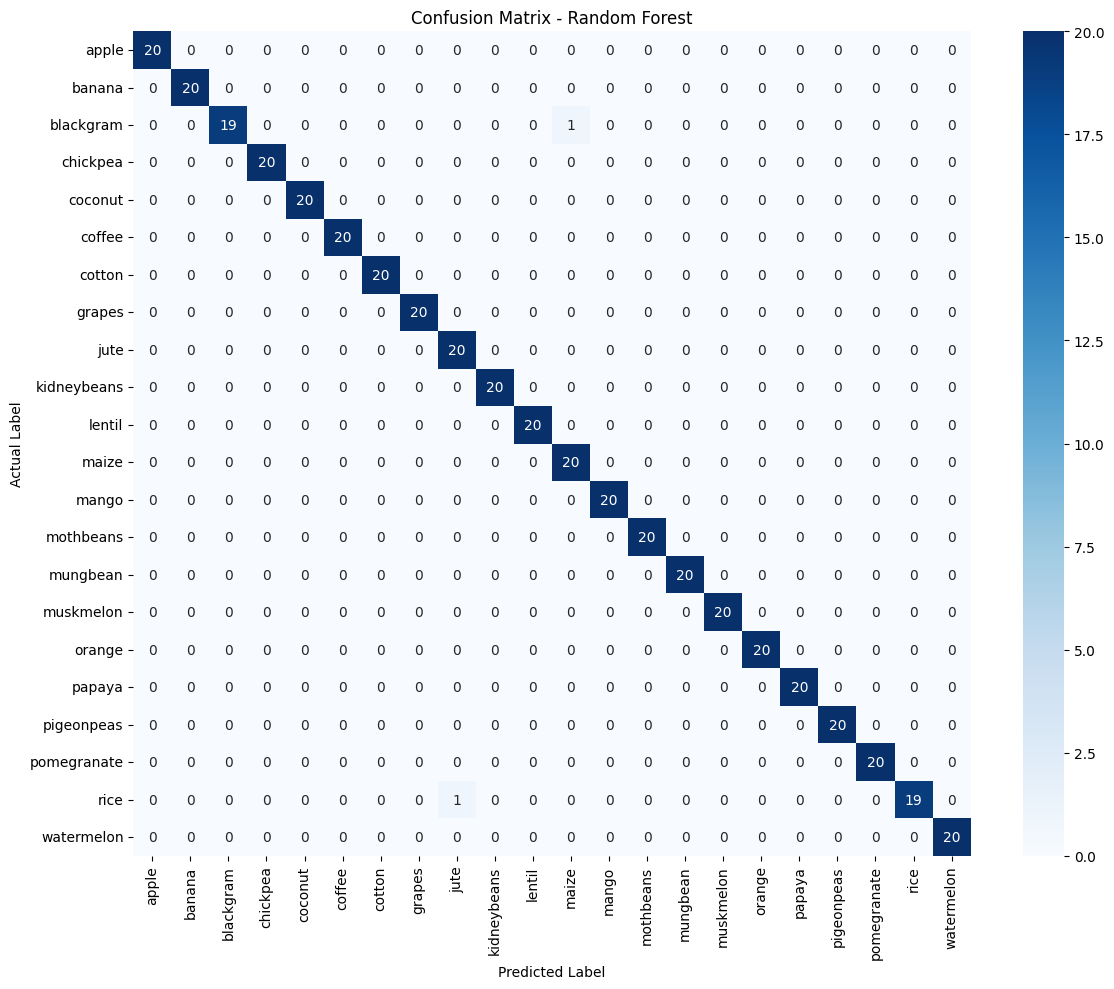

In [6]:
cm_rf = confusion_matrix(y_test, y_pred_rf) # so sánh đáp án thực tế và đáp án mô hình

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",   # định dạng số hiển thị là số nguyên
    cmap="Blues",  # màu tổng thể cho biểu đồ
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

os.makedirs("../reports/figures", exist_ok=True)

plt.savefig(
    "../reports/figures/confusion_matrix_random_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Support Vector Machine (SVM)

Support Vector Machine (SVM) là thuật toán học có giám sát, tìm kiếm siêu phẳng phân tách tối ưu giữa các lớp dữ liệu.

SVM được sử dụng làm mô hình so sánh với Random Forest.

Dữ liệu đầu vào đã được chuẩn hóa từ bước Preprocessing nên phù hợp để sử dụng với SVM.

"rbf" (Radial Basis Function) là một thuật toán toán học giúp SVM bẻ cong không gian, từ đó có thể phân loại được các tập dữ liệu đan xen, méo mó (phi tuyến tính). Đây là kernel phổ biến và mạnh mẽ nhất của SVM.

Gamma quyết định mức độ ảnh hưởng của một điểm dữ liệu lên toàn bộ ranh giới xa hay gần. Bằng cách thiết lập là "scale", đang yêu cầu thư viện scikit-learn tự động tính toán và chọn ra con số Gamma tốt nhất dựa trên số lượng đặc trưng và phương sai của tập dữ liệu đang có (thay vì phải tự đoán một con số).

In [7]:
svm_model = SVC(    # khởi tạo mô hình phân loại
    kernel="rbf",
    C=10,   # mức độ kiểm tra khi mô hình dự đoán sai (C càng lớn mức khắc khe càng cao)
    gamma="scale",
    random_state=42
)

# Huấn luyện
start_time = time.time()

svm_model.fit(X_train, y_train)

svm_train_time = time.time() - start_time

# Dự đoán
start_time = time.time()

y_pred_svm = svm_model.predict(X_test)

svm_predict_time = time.time() - start_time

print(f"Thời gian train     : {svm_train_time:.4f} giây")
print(f"Thời gian dự đoán   : {svm_predict_time:.4f} giây")

Thời gian train     : 0.0275 giây
Thời gian dự đoán   : 0.0144 giây


## 8.1. Đánh giá SVM

SVM được đánh giá trên cùng tập Test và sử dụng cùng các chỉ số Accuracy, Precision và Recall để đảm bảo việc so sánh giữa hai mô hình là nhất quán.

In [8]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)

svm_precision = precision_score(
    y_test,
    y_pred_svm,
    average="weighted",
    zero_division=0
)

svm_recall = recall_score(
    y_test,
    y_pred_svm,
    average="weighted",
    zero_division=0
)

print("===== SVM =====")
print(f"Accuracy : {svm_accuracy:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall   : {svm_recall:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_svm,
        zero_division=0
    )
)

===== SVM =====
Accuracy : 0.9909
Precision: 0.9915
Recall   : 0.9909

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20
           2       1.00      1.00      1.00        20
           3       1.00      1.00      1.00        20
           4       1.00      1.00      1.00        20
           5       1.00      1.00      1.00        20
           6       0.95      1.00      0.98        20
           7       1.00      1.00      1.00        20
           8       0.91      1.00      0.95        20
           9       1.00      1.00      1.00        20
          10       1.00      1.00      1.00        20
          11       1.00      0.95      0.97        20
          12       1.00      1.00      1.00        20
          13       0.95      1.00      0.98        20
          14       1.00      1.00      1.00        20
          15       1.00      1.00      1.

## 8.2. Confusion Matrix - SVM

Confusion Matrix của SVM được trực quan hóa để quan sát khả năng phân biệt giữa các loại cây và xác định các lớp mà mô hình thường nhầm lẫn.

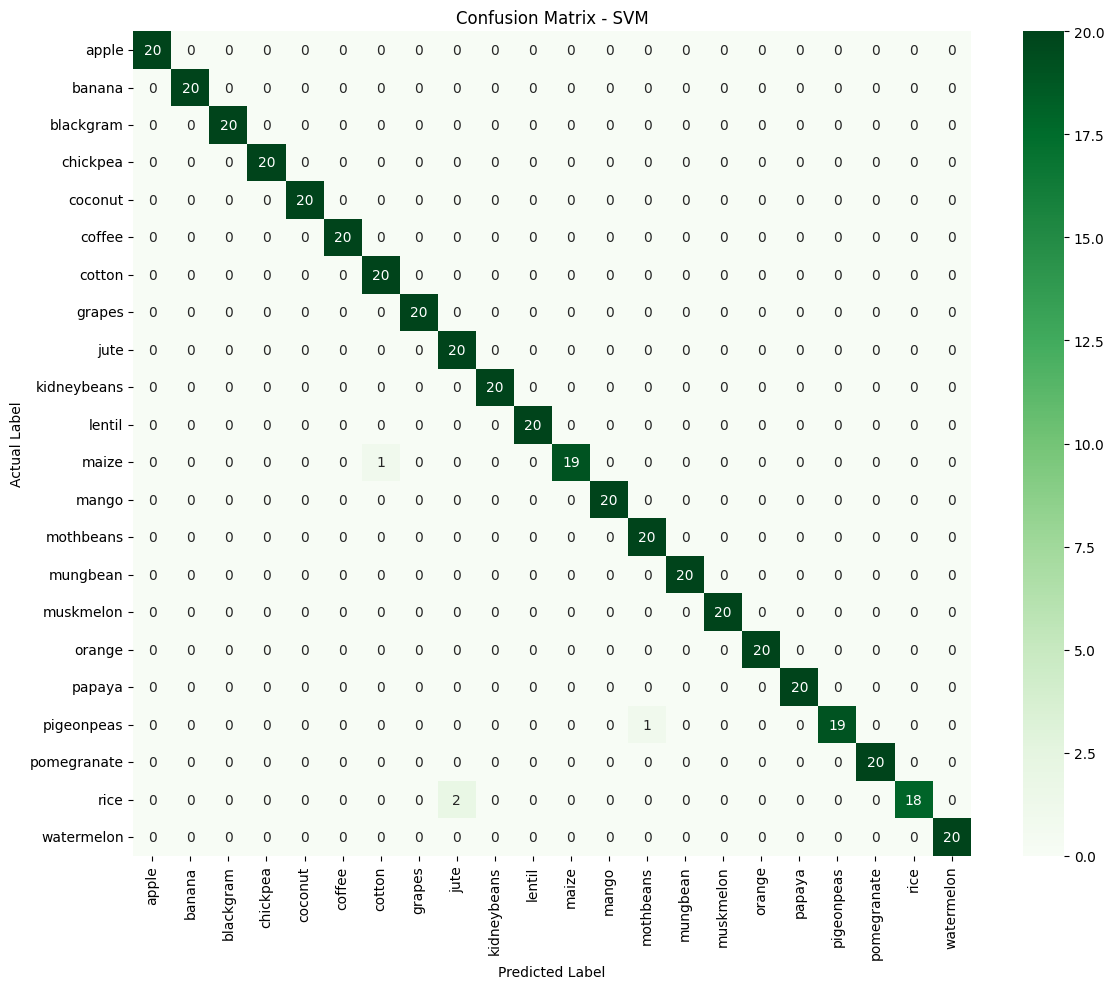

In [9]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix_svm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. So sánh hai mô hình

Random Forest và SVM được đánh giá trên cùng một tập Test.

Việc so sánh dựa trên:

- Accuracy
- Precision
- Recall
- Thời gian huấn luyện
- Thời gian dự đoán

Mô hình có kết quả tốt hơn sẽ được lựa chọn để sử dụng cho các bước tiếp theo của đồ án.

In [10]:
import sys
!{sys.executable} -m pip install jinja2

'C:\Users\Quang' is not recognized as an internal or external command,
operable program or batch file.


In [11]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "SVM"
    ],
    "Accuracy": [
        rf_accuracy,
        svm_accuracy
    ],
    "Precision": [
        rf_precision,
        svm_precision
    ],
    "Recall": [
        rf_recall,
        svm_recall
    ],
    "Train Time (s)": [
        rf_train_time,
        svm_train_time
    ],
    "Predict Time (s)": [
        rf_predict_time,
        svm_predict_time
    ]
})

display(
    comparison.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Train Time (s)": "{:.4f}",
        "Predict Time (s)": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,Train Time (s),Predict Time (s)
0,Random Forest,0.9955,0.9957,0.9955,0.3077,0.0521
1,SVM,0.9909,0.9915,0.9909,0.0275,0.0144


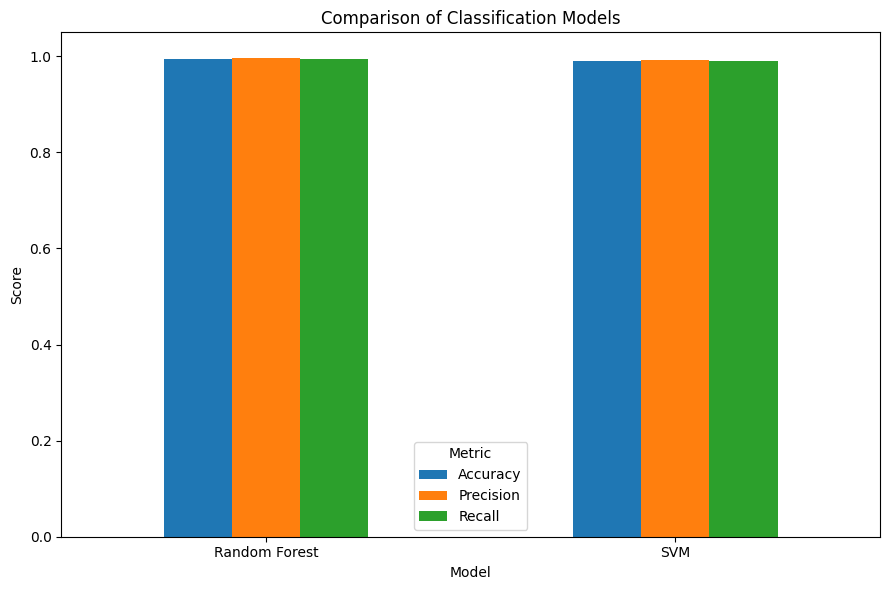

In [12]:
ax = comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall"]
].plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()

plt.savefig(
    "../reports/figures/classification_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9.1. Nhận xét kết quả

Bảng so sánh cho phép đánh giá trực tiếp hiệu quả của Random Forest và SVM trên cùng tập Test.

Accuracy, Precision và Recall được sử dụng để đánh giá chất lượng phân lớp.

Thời gian Train và Predict được sử dụng để so sánh thêm về hiệu năng thực thi của hai mô hình.

# 10. Lựa chọn mô hình tốt nhất

Mô hình tốt nhất được lựa chọn dựa trên Accuracy trên tập Test.

Sau khi xác định mô hình có kết quả tốt nhất, mô hình được lưu dưới dạng file `.pkl` bằng thư viện `joblib`.

File model được lưu trong thư mục `models/` để các thành viên khác có thể sử dụng ở các bước tiếp theo của đồ án.

In [13]:
best_model_name = comparison.loc[
    comparison["Accuracy"].idxmax(),  # tìm giá trị cao nhất và lấy ra vị trí đó
    "Model"
]

if best_model_name == "Random Forest":
    best_model = random_forest
    model_path = "../models/random_forest_model.pkl"
else:
    best_model = svm_model
    model_path = "../models/svm_model.pkl"

os.makedirs("../models", exist_ok=True)

joblib.dump(    # đóng gói mô hình tốt nhất
    best_model,
    model_path
)

best_row = comparison[
    comparison["Model"] == best_model_name
].iloc[0]

print("===== BEST MODEL =====")
print("Mô hình tốt nhất:", best_model_name)
print(f"Accuracy : {best_row['Accuracy']:.4f}")
print(f"Precision: {best_row['Precision']:.4f}")
print(f"Recall   : {best_row['Recall']:.4f}")
print("Đã lưu model tại:", model_path)

===== BEST MODEL =====
Mô hình tốt nhất: Random Forest
Accuracy : 0.9955
Precision: 0.9957
Recall   : 0.9955
Đã lưu model tại: ../models/random_forest_model.pkl


# 11. Feature Importance của Random Forest

Feature Importance cho biết mức độ đóng góp tương đối của từng đặc trưng trong quá trình Random Forest đưa ra dự đoán.

Chỉ số này giúp xác định đặc trưng nào có vai trò quan trọng hơn đối với bài toán dự đoán loại cây trồng.

random_forest.feature_importances_ là một quyền năng của Random Forest. Sau khi học xong, mô hình sẽ tự động chấm điểm xem yếu tố nào giúp nó phân loại tốt nhất và lưu vào thuộc tính này. Ta chỉ việc kéo điểm số đó ra và nhét vào cột.

In [14]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(
    feature_importance.style.format({
        "Importance": "{:.4f}"
    })
)

,Feature,Importance
6,rainfall,0.2209
4,humidity,0.2164
2,K,0.1808
1,P,0.1512
0,N,0.1032
3,temperature,0.0752
5,ph,0.0523


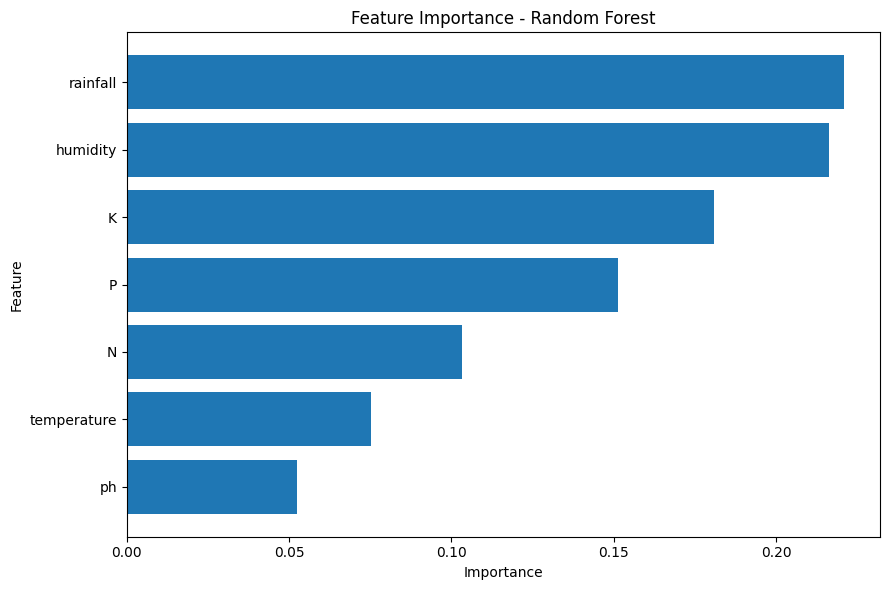

In [15]:
plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Random Forest")

plt.gca().invert_yaxis()  # đảo ngược trục y

plt.tight_layout()

plt.savefig(
    "../reports/figures/random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11.1. Nhận xét Feature Importance

Biểu đồ cho thấy mức độ quan trọng tương đối của 7 đặc trưng đối với mô hình Random Forest.

Đặc trưng có giá trị Importance cao hơn đóng góp nhiều hơn vào quá trình phân loại của mô hình.

# 12. Kết luận

Qua thực nghiệm, Random Forest và SVM được huấn luyện và đánh giá trên cùng một tập Test.

Mô hình tốt nhất được lựa chọn dựa trên kết quả Accuracy, đồng thời xem xét Precision, Recall và thời gian thực thi.

Random Forest được sử dụng làm mô hình chính của bài toán. Mô hình có kết quả tốt nhất được lưu vào thư mục `models/` để sử dụng cho các bước tiếp theo của đồ án.

Các biểu đồ kết quả được lưu trong thư mục `reports/figures/`, bao gồm:

- Confusion Matrix của Random Forest.
- Confusion Matrix của SVM.
- Biểu đồ so sánh hai mô hình.
- Feature Importance của Random Forest.